### Neural network, experimentation tool, version 2, scaled version w/ REAL DATA

EDIT: the scaling is now done seaprately for independent support variables and the target (X and y).

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# activation functions
# ReLu is very simple, it filters out all negative values
# this is a powerful activation function in reality
def activation_ReLu(number):
    if number > 0:
        return number
    else:
        return 0

# we also need a derivated version of ReLu
# otherwise same as original, but instead of origina value, return 1 instead
def activation_ReLu_derivative(number):
    if number > 0:
        return 1
    else:
        return 0

In [29]:
# load the data from csv
df = pd.read_csv("medical_insurance.csv")

# here we replace our:
# x1, x2, y => with "age", "bmi" and "charges"
df = df[['age', 'bmi', 'charges']]
df

,age,bmi,charges
0,19,27.900,16884.92400
1,18,33.770,1725.55230
2,28,33.000,4449.46200
3,33,22.705,21984.47061
4,32,28.880,3866.85520
...,...,...,...
2767,47,45.320,8569.86180
2768,21,34.600,2020.17700
2769,19,26.030,16450.89470
2770,23,18.715,21595.38229


In [30]:
# lock down the randomness in order to get same results everytime
# you can change or disable this if you want
np.random.seed(2026)

def generate_training_data():
    result = []

    # create 100 numbers
    for x in range(100):
        n1 = np.random.randint(0, 5)
        n2 = np.random.randint(3, 7)
        n3 = n1 ** 2 + n2 + np.random.randint(0, 5)

        result.append([n1, n2, n3])

    return result

In [ ]:
# initialize weights and biases
# in Keras/TensorFlow/PyTorch etc. these are usually randomized in the beginning
w1 = 1
w2 = 0.5
w3 = 1
w4 = -0.5
w5 = 1
w6 = 1
bias1 = 0.5
bias2 = 0
bias3 = 0.5

# interesting question to study:
# if we use these as the starting weights and biases
# ... the model again tends to output only bias3 -values?
# ..... but WHY?

# w1 = 1.5
# w2 = 0.5
# w3 = -2
# w4 = -0.5
# w5 = 1.5
# w6 = 1.2
# bias1 = 0.5
# bias2 = -0.35
# bias3 = 0.5

# THEORY => weights/biases should be in the range of -1 to 1
# It seems this might be the case!
w1 = 0.9
w2 = 0.5
w3 = -0.95
w4 = -0.5
w5 = 1
w6 = 0.83
bias1 = 0.52
bias2 = -0.35
bias3 = 0.5

# just for comparison after the training
original_w1 = w1
original_w2 = w2
original_w3 = w3
original_w4 = w4
original_w5 = w5
original_w6 = w6
original_b1 = bias1
original_b2 = bias2
original_b3 = bias3

# DataFrame values as a list
data = df.values

# use min/max -scaling to make values in the range 0-1
# independent support variables => indeces 0 and 1 (X)
# target variable => index 2 (y)
X = data[:, :2]
y = data[:, 2:]

# Scale X and y
X_scaled = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))
y_scaled = (y - np.min(y, axis=0)) / (np.max(y, axis=0) - np.min(y, axis=0))

# combine back to original data format
data = np.hstack((X_scaled, y_scaled))

# learning rate
LR = 0.005
epochs = 1000

# let's initialize a list for loss visualizations
loss_points = []

# training loop
for epoch in range(epochs):

    # the previous version only measured the loss value
    # of the last calculation done in the code (node 3)
    # it's probably better to measure the average loss for each epoch
    epoch_losses = []

    for row in data:
        # this is where we do Forward pass + backpropagation
        input1 = row[0]
        input2 = row[1]
        true_value = row[2]

        # NODE 1 OUTPUT
        node_1_output = input1 * w1 + input2 * w3 + bias1
        node_1_output = activation_ReLu(node_1_output)

        # NODE 2 OUTPUT
        node_2_output = input1 * w2 + input2 * w4 + bias2
        node_2_output = activation_ReLu(node_2_output)

        # NODE 3 OUTPUT
        # we can just use Node 1 and 2 outputs, since they already
        # contain the previous weights in their result
        node_3_output = node_1_output * w5 + node_2_output * w6 + bias3
        node_3_output = activation_ReLu(node_3_output)

        # LOSS FUNCTION - we are going to use MSE -> mean squared error
        # MSE formula for LOSS => (predicted_value - true_value)^2
        predicted_value = node_3_output
        loss = (predicted_value - true_value) ** 2

        # add current loss into epoch losses -list
        epoch_losses.append(loss)

        # BACKPROPAGATION - LAST LAYER FIRST
        # solving the partial derivative of the loss function with respect to w5
        deriv_L_w5 = 2 * node_1_output * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_w5 = w5 - LR * deriv_L_w5

        deriv_L_w6 = 2 * node_2_output * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_w6 = w6 - LR * deriv_L_w6

        deriv_L_b3 = 2 * 1 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_b3 = bias3 - LR * deriv_L_b3

        # BACKPROPAGATION - THE FIRST LAYER
        # FROM THIS POINT ONWARD WE HAVE TO USE THE MORE COMPLEX
        # VERSION OF UPDATING THE VALUES => CHAIN RULE

        # weight 1
        deriv_L_w1_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w1_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * input1
        deriv_L_w1 = deriv_L_w1_left * deriv_L_w1_right
        new_w1 = w1 - LR * deriv_L_w1

        # weight 2
        deriv_L_w2_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w2_right = activation_ReLu_derivative(input1 * w2 + input2 * w4 + bias2) * input1
        deriv_L_w2 = deriv_L_w2_left * deriv_L_w2_right
        new_w2 = w2 - LR * deriv_L_w2

        # weight 3
        deriv_L_w3_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w3_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * input2
        deriv_L_w3 = deriv_L_w3_left * deriv_L_w3_right
        new_w3 = w3 - LR * deriv_L_w3

        # weight 4
        deriv_L_w4_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w4_right = activation_ReLu_derivative(input1 * w2 + input2 * w4 + bias2) * input2
        deriv_L_w4 = deriv_L_w4_left * deriv_L_w4_right
        new_w4 = w4 - LR * deriv_L_w4

        # bias 1
        deriv_L_b1_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_b1_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * 1
        deriv_L_b1 = deriv_L_b1_left * deriv_L_b1_right
        new_b1 = bias1 - LR * deriv_L_b1

        # bias 2
        deriv_L_b2_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_b2_right = activation_ReLu_derivative(input1 * w2 + input2 * w3 + bias2) * 1
        deriv_L_b2 = deriv_L_b2_left * deriv_L_b2_right
        new_b2 = bias2 - LR * deriv_L_b2

        # ALL DONE! FINALLY UPDATE THE EXISTING WEIGHTS
        w1 = new_w1
        w2 = new_w2
        w3 = new_w3
        w4 = new_w4
        w5 = new_w5
        w6 = new_w6
        bias1 = new_b1
        bias2 = new_b2
        bias3 = new_b3

    # calculate average epoch-wise loss and add it to loss points
    average_loss = sum(epoch_losses) / len(epoch_losses)

    # place the overall epoch loss into the loss_points list
    loss_points.append(average_loss)
    print(f"Epoch: {epoch + 1}, loss: {loss}")

Epoch: 1, loss: 0.0022103637964903714
Epoch: 2, loss: 0.0026639587723402496
Epoch: 3, loss: 0.0028293929867662395
Epoch: 4, loss: 0.002879549617021945
Epoch: 5, loss: 0.0029180134904196933
Epoch: 6, loss: 0.0029445128723123784
Epoch: 7, loss: 0.0029578720870220374
Epoch: 8, loss: 0.002968912480702871
Epoch: 9, loss: 0.002973909506875502
Epoch: 10, loss: 0.0029760475584770323
Epoch: 11, loss: 0.002977520857062926
Epoch: 12, loss: 0.0029785369663705564
Epoch: 13, loss: 0.002978743464898747
Epoch: 14, loss: 0.002978894238029779
Epoch: 15, loss: 0.0029790055677717422
Epoch: 16, loss: 0.002979088948353715
Epoch: 17, loss: 0.0029791525019501734
Epoch: 18, loss: 0.0029792019733885775
Epoch: 19, loss: 0.00297924142980688
Epoch: 20, loss: 0.002979273753273901
Epoch: 21, loss: 0.0029793009879762085
Epoch: 22, loss: 0.002979294870991387
Epoch: 23, loss: 0.0029792580249802187
Epoch: 24, loss: 0.002979733722777765
Epoch: 25, loss: 0.0029796474850171716
Epoch: 26, loss: 0.002979562221574384
Epoch: 2

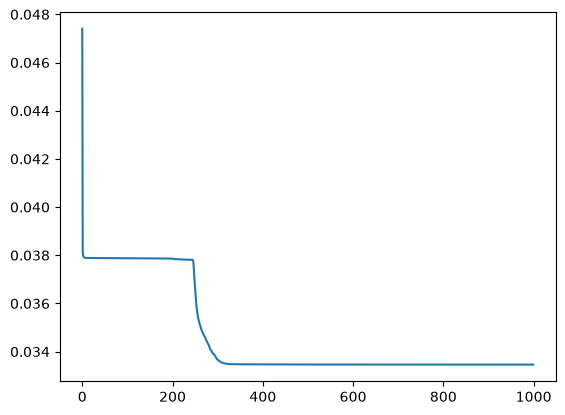

In [32]:
plt.plot(loss_points)

# we can limit the y-axis to see the learning better
# plt.ylim(-1, 3)
plt.show()

In [33]:
print("ORIGINAL WEIGHTS AND BIASES")
print(f"w1: {original_w1}")
print(f"w2: {original_w2}")
print(f"w3: {original_w3}")
print(f"w4: {original_w4}")
print(f"w5: {original_w5}")
print(f"w6: {original_w6}")
print(f"b1: {original_b1}")
print(f"b2: {original_b2}")
print(f"b3: {original_b3}")

print("\n\n##################################")

print("NEW WEIGHTS AND BIASES")
print(f"w1: {w1}")
print(f"w2: {w2}")
print(f"w3: {w3}")
print(f"w4: {w4}")
print(f"w5: {w5}")
print(f"w6: {w6}")
print(f"b1: {bias1}")
print(f"b2: {bias2}")
print(f"b3: {bias3}")


ORIGINAL WEIGHTS AND BIASES
w1: 0.9
w2: 0.5
w3: -0.95
w4: -0.5
w5: 1
w6: 0.83
b1: 0.52
b2: -0.35
b3: 0.5


##################################
NEW WEIGHTS AND BIASES
w1: 0.4912539044430315
w2: 0.12984658830352466
w3: 0.5510569819172255
w4: -0.5461467072568347
w5: 0.35955374598702033
w6: 0.8168475810829328
b1: -0.07153939322646234
b2: -0.1160648056671922
b3: 0.06821163957329694


In [34]:
# prediction function, JUST DO THE FORWARD PASS
# (forward pass again, BUT ONLY THAT!)
def predict(x1, x2):
    input1 = x1
    input2 = x2

    # NODE 1 OUTPUT
    node_1_output = input1 * w1 + input2 * w3 + bias1
    node_1_output = activation_ReLu(node_1_output)

    # NODE 2 OUTPUT
    node_2_output = input1 * w2 + input2 * w4 + bias2
    node_2_output = activation_ReLu(node_2_output)

    # NODE 3 OUTPUT
    # we can just use Node 1 and 2 outputs, since they already
    # contain the previous weights in their result
    node_3_output = node_1_output * w5 + node_2_output * w6 + bias3
    node_3_output = activation_ReLu(node_3_output)
    return node_3_output

Let's try with actual data.

In [35]:
df

,age,bmi,charges
0,19,27.900,16884.92400
1,18,33.770,1725.55230
2,28,33.000,4449.46200
3,33,22.705,21984.47061
4,32,28.880,3866.85520
...,...,...,...
2767,47,45.320,8569.86180
2768,21,34.600,2020.17700
2769,19,26.030,16450.89470
2770,23,18.715,21595.38229


In [36]:
# index 543 is on of the biggest charges in the data
df.iloc[543]

age           54.00000
bmi           47.41000
charges    63770.42801
Name: 543, dtype: float64

In [37]:
# scaled values
data[543]

array([0.7826087 , 0.84611246, 1.        ])

In [38]:
# ~ $ 63770 
df['charges'].max() * 1

np.float64(63770.42801)

In [ ]:
# try using the model with our predict-function
result = predict(0.7826087 , 0.84611246)
result

np.float64(0.3483674203467764)

In [ ]:
# undershoots heavily, but the model seems to react correctly
# to different x-values!
df['charges'].max() * result

np.float64(22215.539500253515)